# **Install required libraries**

In [1]:
!pip install datasets torch torchvision matplotlib pillow pandas scikit-learn

   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   --------------------------------------- 608.3/608.3 kB 11.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
    --------------------------------------- 2.1/126.7 MB 9.8 MB/s eta 0:00:13
   - -------------------------------------- 4.7/126.7 MB 10.9 MB/s eta 0:00:12
   -- ------------------------------------- 6.8/126.7 MB 11.0 MB/s eta 0:00:11
   -- ------------------------------------- 9.2/126.7 MB 10.8 MB/s eta 0:00:11
   --- ------------------------------------ 11.3/126.7 MB 10.8 MB/s eta 0:00:11
   ---- ----------------------------------- 13.4/126.7 MB 10.6 MB/s eta 0:00:11
   ---- ----------------------------------- 15.5/126.7 MB 10.5 MB/s eta 0:00:11
   ----- ---------------------------------- 17.6/126.7 MB 10.3 MB/s eta 0:00:11
   ----- ---------------------------------- 18.9/126.7 MB 10.4 MB/s eta 0:00:11
   ------ --------------------------------- 19.7/126.7 MB 9.7 M


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# **Load the OCT dataset from Hugging Face**

In [2]:
from datasets import load_dataset

ds = load_dataset("zacharielegault/Kermany2017-OCT")

print(ds)

c:\Users\deepi\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\deepi\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\deepi\.cache\huggingface\hub\datasets--zacharielegault--Kermany2017-OCT. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Pyt

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})


In [3]:
print(ds.keys())

dict_keys(['train', 'test'])


# **Access training and testing data**

In [4]:
train_data = ds["train"]
test_data = ds["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print(train_data.features)

Training samples: 108309
Testing samples: 1000
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}


# **Access an individual image**

Label: 0
Image size: (512, 496)
Image mode: L


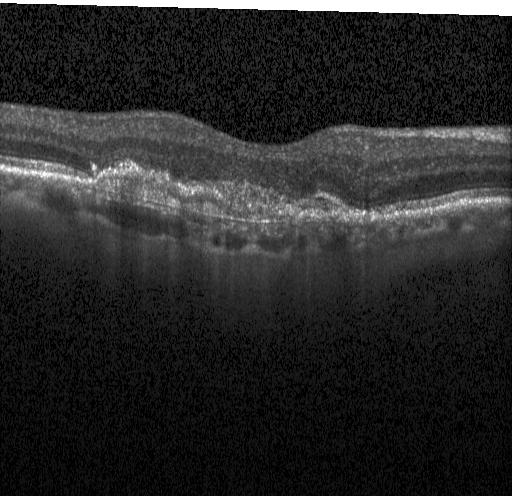

In [5]:
sample = train_data[0]

image = sample["image"]
label = sample["label"]

print("Label:", label)
print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

# **Understand the class labels**

In [6]:
label_names = train_data.features["label"].names

print(label_names)

['CNV', 'DME', 'DRUSEN', 'NORMAL']


# **Visualize multiple images**

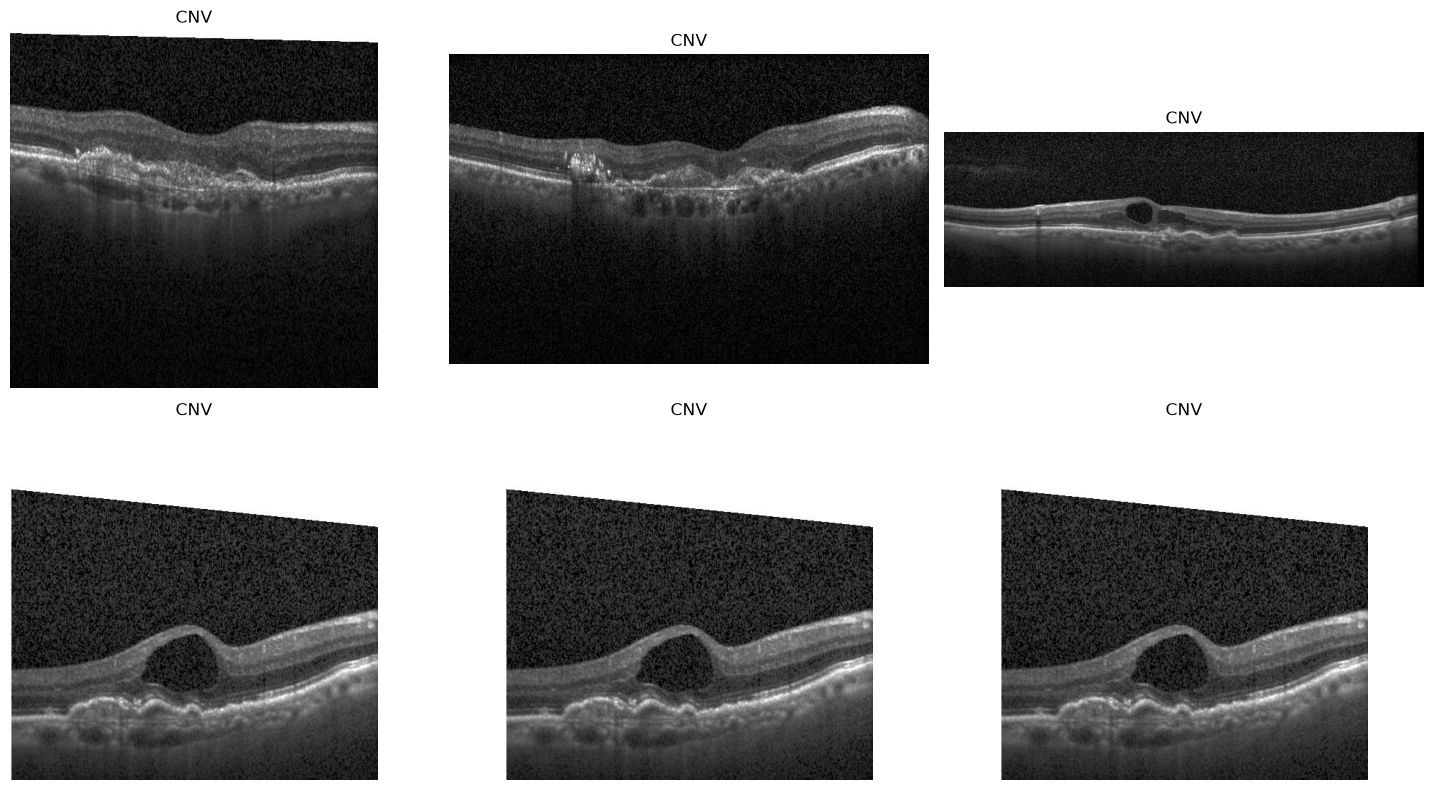

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, ax in enumerate(axes.flat):
    sample = train_data[i]

    ax.imshow(sample["image"], cmap="gray")
    ax.set_title(label_names[sample["label"]])
    ax.axis("off")

plt.tight_layout()
plt.show()

2. Image Exploration and Preprocessing

Visualize sample images from all four categories.

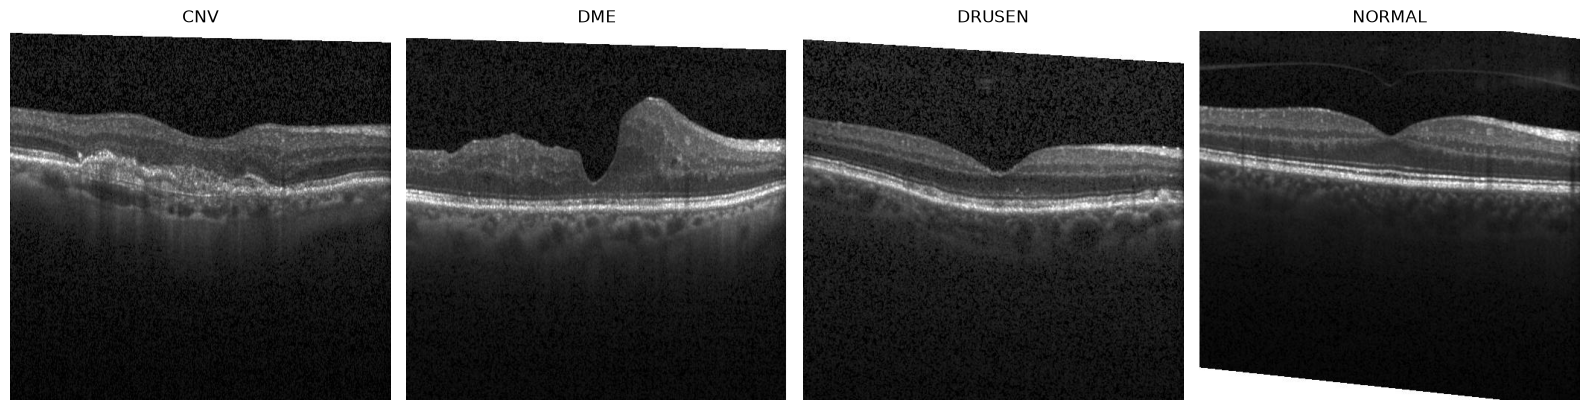

In [ ]:
import matplotlib.pyplot as plt

label_names = train_data.features["label"].names

# Get all labels without loading all images
labels = train_data["label"]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for label_id, ax in enumerate(axes):

    # Find the index of the first occurrence of each class
    index = labels.index(label_id)

    # Load only that image
    sample = train_data[index]

    ax.imshow(sample["image"], cmap="gray")
    ax.set_title(label_names[label_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

Check Class Distribution

In [9]:
from collections import Counter

train_labels = train_data["label"]

class_counts = Counter(train_labels)

for label_id, count in sorted(class_counts.items()):
    print(f"{label_names[label_id]}: {count}")

CNV: 37205
DME: 11348
DRUSEN: 8616
NORMAL: 51140


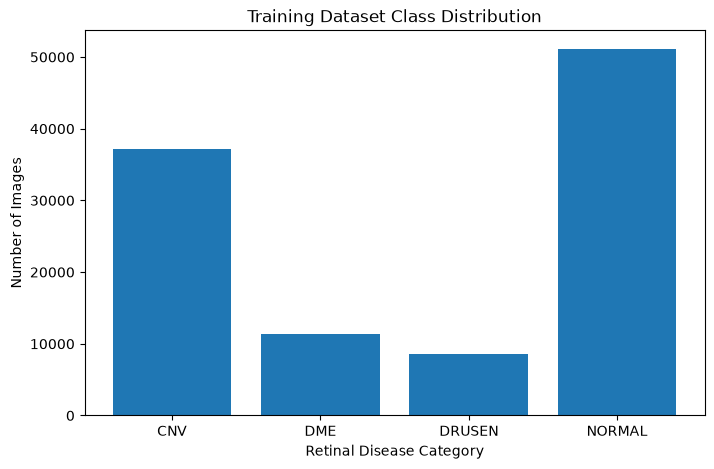

In [10]:
classes = list(label_names)
counts = [class_counts[i] for i in range(len(classes))]

plt.figure(figsize=(8, 5))
plt.bar(classes, counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Retinal Disease Category")
plt.ylabel("Number of Images")

plt.show()

Analyze image dimensions, quality, and variations.

In [11]:
import random

# Select 20 random indices
random_indices = random.sample(
    range(len(train_data)),
    20
)

image_sizes = []

for index in random_indices:
    image = train_data[index]["image"]
    image_sizes.append(image.size)

print("Image sizes from 20 random samples:")

for size in image_sizes:
    print(size)

Image sizes from 20 random samples:
(512, 496)
(512, 496)
(768, 496)
(768, 496)
(512, 496)
(768, 496)
(512, 496)
(512, 496)
(512, 496)
(1536, 496)
(768, 496)
(512, 512)
(512, 496)
(512, 496)
(1536, 496)
(768, 496)
(768, 496)
(768, 496)
(512, 496)
(768, 496)


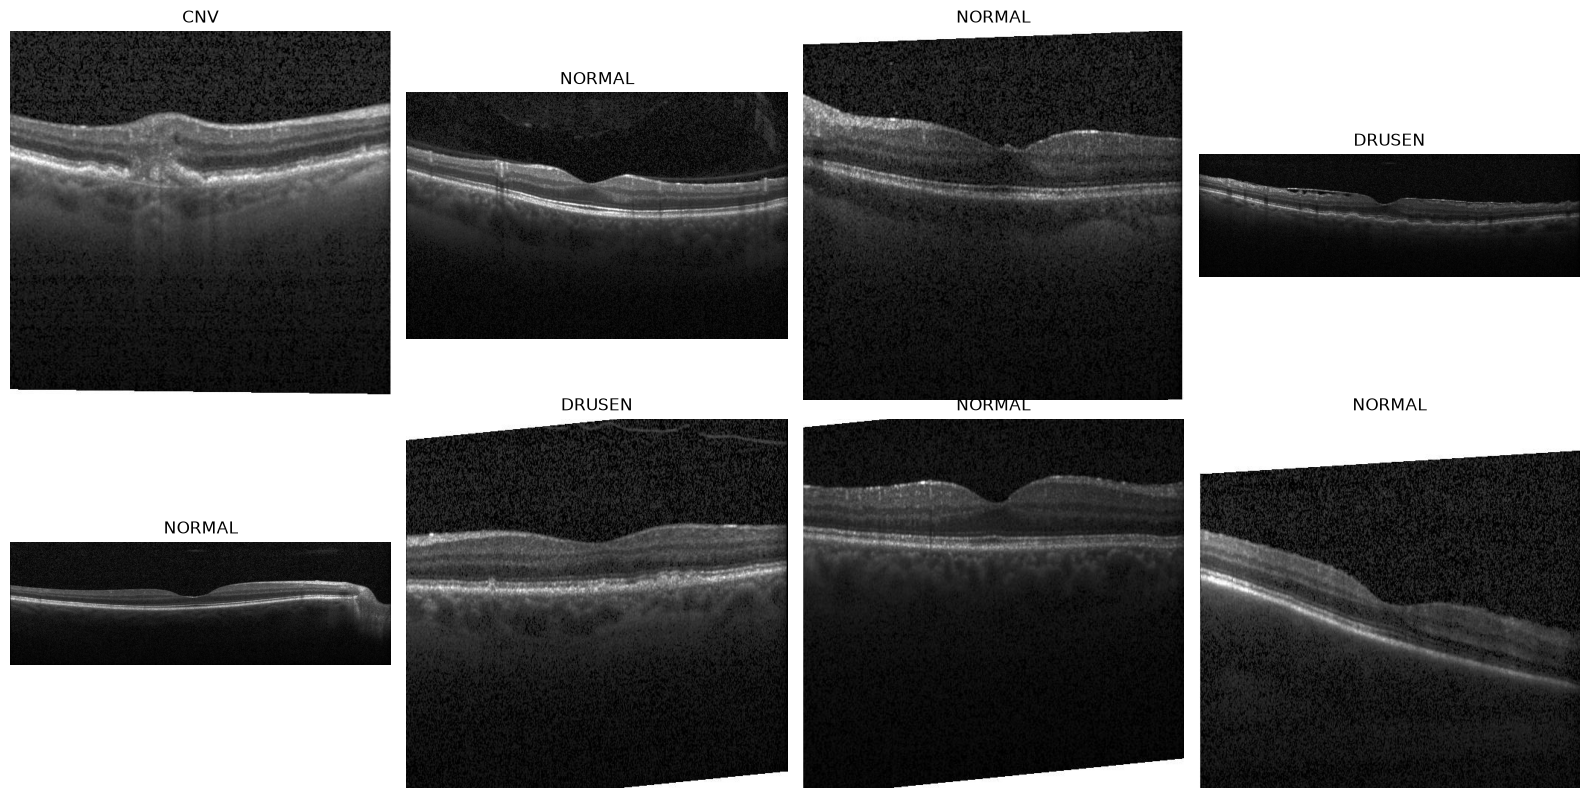

In [12]:
# Select 8 random images
random_indices = random.sample(range(len(train_data)), 8)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for index, ax in zip(random_indices, axes.flat):

    sample = train_data[index]
    image = sample["image"]
    label = sample["label"]

    ax.imshow(image, cmap="gray")
    ax.set_title(label_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
from torchvision import transforms

# Create a resize transformation
resize_transform = transforms.Resize((224, 224))

# Select one sample image
sample_image = train_data[0]["image"]

# Apply resizing
resized_image = resize_transform(sample_image)

print("Original size:", sample_image.size)
print("Resized size:", resized_image.size)

Original size: (512, 496)
Resized size: (224, 224)


In [14]:
#Test the transformation on one image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

sample_image = train_data[0]["image"]

image_tensor = transform(sample_image)

print("Tensor shape:", image_tensor.shape)
print("Data type:", image_tensor.dtype)
print("Minimum value:", image_tensor.min())
print("Maximum value:", image_tensor.max())

Tensor shape: torch.Size([1, 224, 224])
Data type: torch.float32
Minimum value: tensor(0.0039)
Maximum value: tensor(1.)


In [15]:
#normalization
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

sample_image = train_data[0]["image"]

normalized_tensor = transform(sample_image)

print("Tensor shape:", normalized_tensor.shape)
print("Minimum value:", normalized_tensor.min())
print("Maximum value:", normalized_tensor.max())

Tensor shape: torch.Size([1, 224, 224])
Minimum value: tensor(-0.9922)
Maximum value: tensor(1.)


In [16]:
#Augementation for single image

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [17]:
sample_image = train_data[0]["image"]

augmented_tensor = train_transform(sample_image)

print("Augmented tensor shape:", augmented_tensor.shape)
print("Minimum value:", augmented_tensor.min())
print("Maximum value:", augmented_tensor.max())

Augmented tensor shape: torch.Size([1, 224, 224])
Minimum value: tensor(-1.)
Maximum value: tensor(1.)


In [18]:
# Split the original training dataset into training and validation sets

split_data = train_data.train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label"
)

actual_train_data = split_data["train"]
val_data = split_data["test"]

print("Training samples:", len(actual_train_data))
print("Validation samples:", len(val_data))

Training samples: 86647
Validation samples: 21662


In [19]:
# Training transformation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Validation and Test transformation
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [20]:
test_data = ds["test"]

# Apply transformations to each dataset

train_dataset = actual_train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            train_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

val_dataset = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

test_dataset = test_data.with_transform(
    lambda examples: {
        "pixel_values": [
            eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

print("Transforms applied successfully!")

Transforms applied successfully!


Create PyTorch DataLoaders

In [21]:
from torch.utils.data import DataLoader

# Batch size
batch_size = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 2708
Validation batches: 677
Test batches: 32


Inspect one batch

In [22]:
# Get one batch from the training DataLoader
batch = next(iter(train_loader))

print("Keys in batch:", batch.keys())

print("Image batch shape:", batch["pixel_values"].shape)
print("Label batch shape:", batch["label"].shape)

print("\nFirst 10 labels:")
print(batch["label"][:10])

Keys in batch: dict_keys(['pixel_values', 'label'])
Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])

First 10 labels:
tensor([2, 1, 2, 0, 0, 0, 1, 3, 0, 3])
